In [1]:
from pathlib import Path
import mne
import numpy as np
import matplotlib.pyplot as plt
project_root = Path.cwd().parent
eeg_file = project_root / "data" / "raw" / "chb01" / "chb01_03.edf"
print(eeg_file)
print("Exists:", eeg_file.exists()) #checks if chb01_03 can be read

raw = mne.io.read_raw_edf(
    eeg_file,
    preload=True,
    verbose=False
)


sfreq = raw.info["sfreq"]

print(raw)
print("Sampling frequency:", sfreq)
print("Number of channels:", len(raw.ch_names))

c:\seizure-detection-ML-project\data\raw\chb01\chb01_03.edf
Exists: True
<RawEDF | chb01_03.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>
Sampling frequency: 256.0
Number of channels: 23


C:\Users\rahma\AppData\Local\Temp\ipykernel_21892\1894745312.py:10: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(


Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


C:\Users\rahma\AppData\Local\Temp\ipykernel_21892\3031456031.py:13: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  psd.plot()


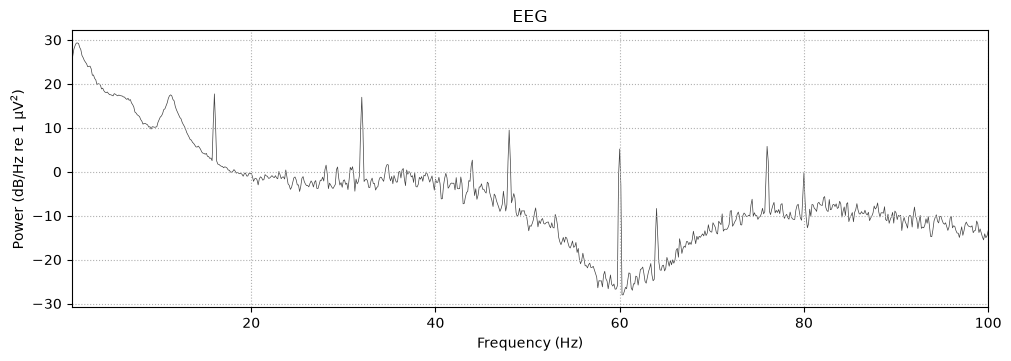

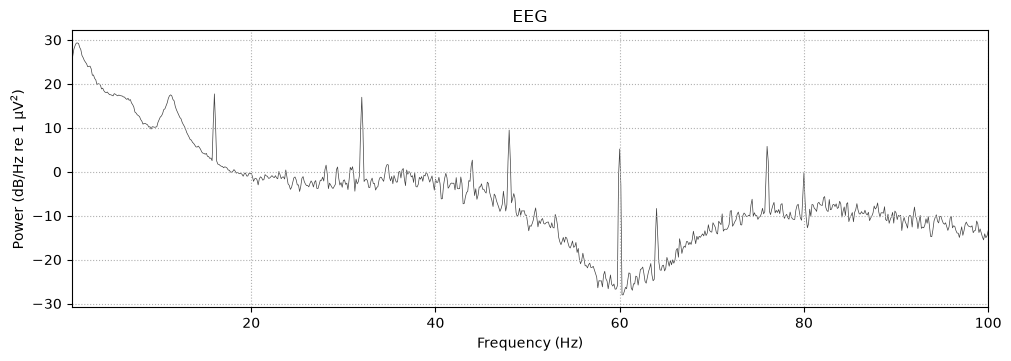

In [2]:
#Will filter EEG data to remove unwanted contentlike baseline drift, 60Hz electrical noise
#&hgiher freq electrode noise

raw_filtered = raw.copy()
#psd = Power Spectral Density, measurs power distibution across diff. freqs
psd = raw.compute_psd(
    picks=["FP1-F7"], 
    fmin=0.5, 
    fmax=100, 
    n_fft=2048
)

psd.plot()

In [3]:
#Important to notice the spike at 60Hz, so should apply a notch filter to remove 60Hz noise
#0.5 - 40Hz band pass filter:
    #High pass at 0.5 Hz
    #-> removes freq below 0.5 Hz

    #Low pass at 40 Hz
    #-> removes freq above 40 Hz
    #->Therefore also removes the 60Hz noise spike
raw_filtered.filter(
    l_freq=0.5,
    h_freq=40,
    picks=["FP1-F7"]
)



Filtering a subset of channels. The highpass and lowpass values in the measurement info will not be updated.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1691 samples (6.605 s)



<RawEDF | chb01_03.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>

Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


C:\Users\rahma\AppData\Local\Temp\ipykernel_21892\1893624696.py:9: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  filtered_psd.plot()


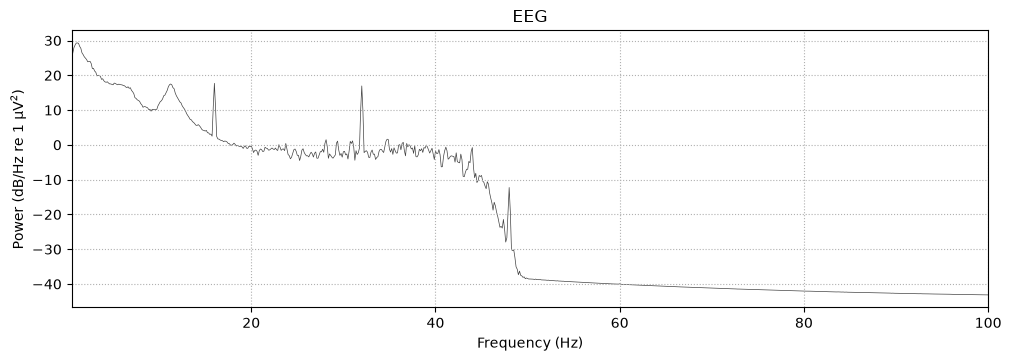

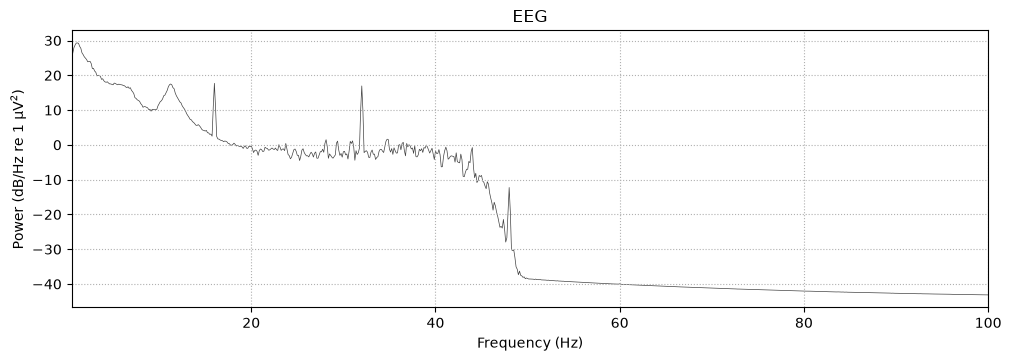

In [4]:
#Checking if filter notch worked:
filtered_psd = raw_filtered.compute_psd(
    picks=["FP1-F7"],
    fmin=0.5,
    fmax=100,
    n_fft=2048
)

filtered_psd.plot()

In [5]:
start_time = 0
end_time = 5
start_sample = int(start_time * sfreq)
end_sample = int(end_time * sfreq)

raw_data, raw_times = raw.get_data(picks=["FP1-F7"], start=start_sample, stop=end_sample, return_times=True)
raw_uv = raw_data[0] * 1e06

filtered_data, filtered_times = raw_filtered.get_data(picks=["FP1-F7"], start=start_sample, stop=end_sample, return_times=True)
filtered_uv = filtered_data[0] * 1e06

print(raw_uv.shape)
print(filtered_uv.shape)
print(raw_uv[:5])
print(filtered_uv[:5])


(1280,)
(1280,)
[-17.77777778   0.1953602    0.1953602    0.58608059   0.1953602 ]
[6.77626358e-15 1.26632164e+01 1.99697356e+01 2.03786020e+01
 1.69318368e+01]


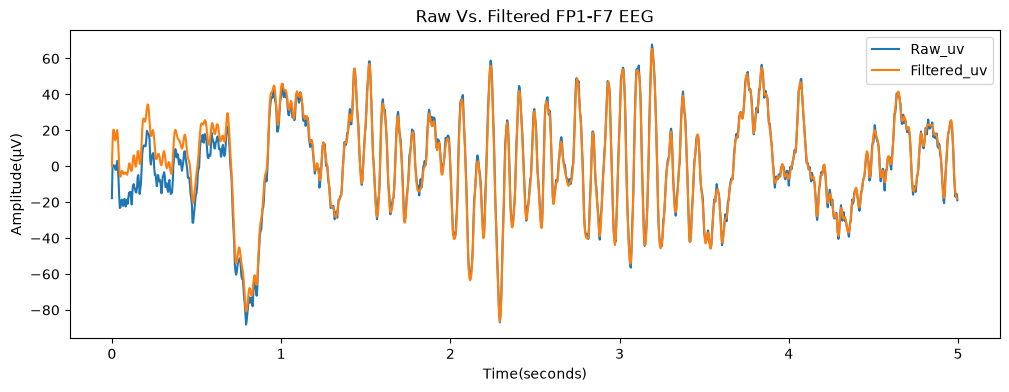

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(raw_times, raw_uv, label=("Raw_uv"))
plt.plot(filtered_times, filtered_uv, label=("Filtered_uv"))
plt.xlabel("Time(seconds)")
plt.ylabel(("Amplitude(µV)"))
plt.title("Raw Vs. Filtered FP1-F7 EEG")
plt.legend()
plt.show()


In [7]:
raw_std = np.std(raw_uv)
filtered_std = np.std(filtered_uv)

raw_rms = np.sqrt(np.mean(raw_uv**2))
filtered_rms = np.sqrt(np.mean(filtered_uv**2))

raw_ptp = np.ptp(raw_uv)
filtered_ptp = np.ptp(filtered_uv)

print(raw_std, raw_rms, raw_ptp)
print(filtered_std, filtered_rms, filtered_ptp)




27.234515605067216 27.238121948168022 155.89743589743588
27.041128862818667 27.11143923382214 152.0404202903048


In [8]:
start_time_seizure = 3000
end_time_seizure = 3005

start_sample = int(start_time_seizure * sfreq)
end_sample = int(end_time_seizure * sfreq)

raw_data, raw_times = raw.get_data(picks=["FP1-F7"], start=start_sample, stop=end_sample, return_times=True)
raw_uv = raw_data[0] * 1e06

filtered_data, filtered_times = raw_filtered.get_data(picks=["FP1-F7"], start=start_sample, stop=end_sample, return_times=True)
filtered_uv = filtered_data[0] * 1e06

print(raw_uv.shape)
print(filtered_uv.shape)
print(raw_uv[:5])
print(filtered_uv[:5])


(1280,)
(1280,)
[-45.51892552 -52.55189255 -56.45909646 -51.77045177 -67.78998779]
[-38.47131235 -40.96234132 -44.62035702 -49.66800555 -54.80275548]


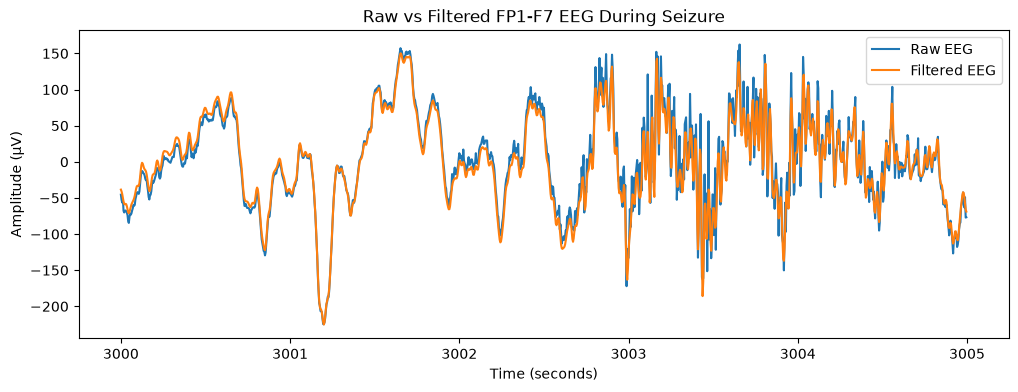

In [9]:
plt.figure(figsize=(12, 4))

plt.plot(raw_times, raw_uv, label="Raw EEG")
plt.plot(filtered_times, filtered_uv, label="Filtered EEG")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (µV)")
plt.title("Raw vs Filtered FP1-F7 EEG During Seizure")
plt.legend()

plt.show()

In [10]:
raw_std = np.std(raw_uv)
filtered_std = np.std(filtered_uv)

raw_rms = np.sqrt(np.mean(raw_uv**2))
filtered_rms = np.sqrt(np.mean(filtered_uv**2))

raw_ptp = np.ptp(raw_uv)
filtered_ptp = np.ptp(filtered_uv)

print(raw_std, raw_rms, raw_ptp)
print(filtered_std, filtered_rms, filtered_ptp)




65.6132599760385 65.66466193146128 387.2039072039072
63.35140218641775 63.35221143202548 375.2431166018107


In [11]:
preprocessed_raw = raw.copy()
preprocessed_raw.filter(
    l_freq=0.5,
    h_freq=40,
    picks="eeg"
)
#Filters through all 21 channels rather than only FP1-F7

print(raw)
print(preprocessed_raw)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1691 samples (6.605 s)

<RawEDF | chb01_03.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>
<RawEDF | chb01_03.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>


In [12]:
start_time = 0
end_time = 5
start_sample = int(start_time * sfreq)
end_sample = int(end_time * sfreq)
raw_data, raw_times = raw.get_data(picks="FP1-F7", start = start_sample, stop = end_sample, return_times=True)
preprocessed_data, preprocessed_times = preprocessed_raw.get_data(picks="FP1-F7", start = start_sample, stop = end_sample, return_times=True)

raw_uv = raw_data[0] * 1e6
preprocessed_uv = preprocessed_data[0] * 1e6

print("Raw:", raw_uv[:5])
print("Preprocessed:", preprocessed_uv[:5])

print("Raw shape:", raw_uv.shape)
print("Preprocessed shape:", preprocessed_uv.shape)


Raw: [-17.77777778   0.1953602    0.1953602    0.58608059   0.1953602 ]
Preprocessed: [6.77626358e-15 1.26632164e+01 1.99697356e+01 2.03786020e+01
 1.69318368e+01]
Raw shape: (1280,)
Preprocessed shape: (1280,)


In [13]:
start_time = 100
end_time = 105
start_sample = int(start_time * sfreq)
end_sample = int(end_time * sfreq)
raw_data, raw_times = raw.get_data(picks="FP1-F7", start = start_sample, stop = end_sample, return_times=True)
preprocessed_data, preprocessed_times = preprocessed_raw.get_data(picks="FP1-F7", start = start_sample, stop = end_sample, return_times=True)

raw_uv = raw_data[0] * 1e6
preprocessed_uv = preprocessed_data[0] * 1e6

print("Raw:", raw_uv[:5])
print("Preprocessed:", preprocessed_uv[:5])



Raw: [-0.58608059 -1.75824176  1.36752137  5.66544567 10.35409035]
Preprocessed: [-1.91990405 -1.35093846  0.45372252  3.27046697  6.53715185]


In [14]:
mean_abs_difference = np.mean(np.abs(raw_uv - preprocessed_uv))

print("Mean absolute difference:", mean_abs_difference, "µV")

Mean absolute difference: 2.2343380967561037 µV


In [15]:
start_time = 3000
end_time = 3005
start_sample = int(start_time * sfreq)
end_sample = int(end_time * sfreq)
preprocessed_data, preprocessed_times = preprocessed_raw.get_data(
    picks="FP1-F7",
    start=start_sample,
    stop=end_sample,
    return_times=True
)

preprocessed_uv = preprocessed_data[0] * 1e6
print(preprocessed_uv.shape)

(1280,)


In [21]:
recording_duration = 3600
window_size = 5
seizure_start = 2996
seizure_end = 3036
num_windows = int(recording_duration / window_size)

windows = []

for window in range(num_windows):
    start_time = window * window_size   
    end_time = start_time + window_size
    if start_time >= seizure_start and end_time <= seizure_end:
        label = "Seizure"
    elif end_time <= seizure_start or start_time >= seizure_end:
        label = "Non-Seizure"
    else:
        label = "Partial-Seizure"

    if label != "Partial-Seizure":
        windows.append({
            "window_index": window,
            "start_time": start_time,
            "end_time": end_time,
            "label": label
        })



print("Usable windows:", len(windows))



Usable windows: 718


In [22]:
import pandas as pd
windows_df = pd.DataFrame(windows)
print(windows_df.head())
print()
print("Total usable windows:", len(windows_df))
print()
print(windows_df["label"].value_counts())

   window_index  start_time  end_time        label
0             0           0         5  Non-Seizure
1             1           5        10  Non-Seizure
2             2          10        15  Non-Seizure
3             3          15        20  Non-Seizure
4             4          20        25  Non-Seizure

Total usable windows: 718

label
Non-Seizure    711
Seizure          7
Name: count, dtype: int64


In [24]:
feature_rows = []
for index, row in windows_df.iterrows():
        start_sample = int(row["start_time"] * sfreq)
        end_sample = int(row["end_time"] * sfreq)
        data, times = preprocessed_raw.get_data(picks="FP1-F7", start=start_sample, stop=end_sample, return_times=True)
        data_uv = data[0] * 1e6
    
        mean_uv = np.mean(data_uv)
        std_uv = np.std(data_uv)
        rms_uv = np.sqrt(np.mean(data_uv ** 2))
        ptp_uv = np.ptp(data_uv)
    
        feature_rows.append({
            "window_index": row["window_index"],
            "start_time": row["start_time"],
            "end_time": row["end_time"],
            "label": row["label"],
            "mean": mean_uv,
            "std_dev": std_uv,
            "rms": rms_uv,
            "ptp": ptp_uv
        })


print(feature_rows)
print("Feature rows:", len(feature_rows))
    

[{'window_index': 0, 'start_time': 0, 'end_time': 5, 'label': 'Non-Seizure', 'mean': np.float64(1.9512783383375996), 'std_dev': np.float64(27.041128862818667), 'rms': np.float64(27.11143923382214), 'ptp': np.float64(152.0404202903048)}, {'window_index': 1, 'start_time': 5, 'end_time': 10, 'label': 'Non-Seizure', 'mean': np.float64(-0.06429760623903942), 'std_dev': np.float64(26.0309991844794), 'rms': np.float64(26.031078593184247), 'ptp': np.float64(167.2694315970155)}, {'window_index': 2, 'start_time': 10, 'end_time': 15, 'label': 'Non-Seizure', 'mean': np.float64(-1.8934567707400825), 'std_dev': np.float64(35.670337342009894), 'rms': np.float64(35.720556331550135), 'ptp': np.float64(233.27739162168854)}, {'window_index': 3, 'start_time': 15, 'end_time': 20, 'label': 'Non-Seizure', 'mean': np.float64(1.8666532175182091), 'std_dev': np.float64(23.43245604516905), 'rms': np.float64(23.50668820874711), 'ptp': np.float64(127.39867225860688)}, {'window_index': 4, 'start_time': 20, 'end_tim

In [25]:
preprocessed_features_df = pd.DataFrame(feature_rows)

print("Rows:", len(preprocessed_features_df))
print()

print("Labels:")
print(preprocessed_features_df["label"].value_counts())

print()
print("Missing values:")
print(preprocessed_features_df.isnull().sum())

print()
print(preprocessed_features_df.head())


Rows: 718

Labels:
label
Non-Seizure    711
Seizure          7
Name: count, dtype: int64

Missing values:
window_index    0
start_time      0
end_time        0
label           0
mean            0
std_dev         0
rms             0
ptp             0
dtype: int64

   window_index  start_time  end_time        label      mean    std_dev  \
0             0           0         5  Non-Seizure  1.951278  27.041129   
1             1           5        10  Non-Seizure -0.064298  26.030999   
2             2          10        15  Non-Seizure -1.893457  35.670337   
3             3          15        20  Non-Seizure  1.866653  23.432456   
4             4          20        25  Non-Seizure -0.217540  30.574674   

         rms         ptp  
0  27.111439  152.040420  
1  26.031079  167.269432  
2  35.720556  233.277392  
3  23.506688  127.398672  
4  30.575448  205.380661  


In [27]:
preprocessed_path = project_root / "data" / "processed" / "chb01_03_fp1-f7_preprocessed_features.csv"
preprocessed_features_df.to_csv(preprocessed_path,
                                index=False)


print("Saved:", processed_path.exists())
print(processed_path)

Saved: True
c:\seizure-detection-ML-project\data\processed\chb01_03_fp1-f7_preprocessed_features.csv


In this notebook I examined the Power Spectral Density graph of the FP1-F7 channel and noticed the prominent spike near 60hz, indicating electral line noise. As a result, I applied a 0.5-40Hz band-pass filter over the EEG recording in order to filter out low frequency drift and high frequency noise. I then segmented the hour-long recording into non-overlapping 5-second windows and labeled them based on seizure or non-sezure values, excluding the partial-seizure windows. This provided me with 718 usable windows, from which I extracted feature values for the preprocessed FP1-F7 signal and saved the feature dataset in a CSV file.